           Section                  Metric Wells Fargo & Company (WFC)  \
0  Market snapshot       Ticker / exchange                  WFC / NYSE   
1  Market snapshot  Latest available price                      $79.93   
2  Market snapshot   Market capitalization                  $241.708bn   
3  Market snapshot      Shares outstanding                         NaN   
4  Market snapshot        Trailing revenue                         NaN   

  The Walt Disney Company (DIS)  
0                    DIS / NYSE  
1    $104.75 (7 Oct 2026 close)  
2               About $180.87bn  
3                  About 1.73bn  
4                      $98.86bn  
['Section', 'Metric', 'Wells Fargo & Company (WFC)', 'The Walt Disney Company (DIS)']

Cluster counts:
 Cluster
0    23
1    20
Name: count, dtype: int64

Silhouette score: 0.03720943144301335

Cluster 0 keywords:
['disney', 'fiscal', '2025', 'segments', 'income', 'operating', 'outlook', 'revenue', 'balance', 'sheet']

Cluster 1 keywords:
['market',

/var/folders/88/w4w1n8l12kd_z42_6mrnndmw0000gn/T/ipykernel_11041/1105377560.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = df.select_dtypes(include="object").columns


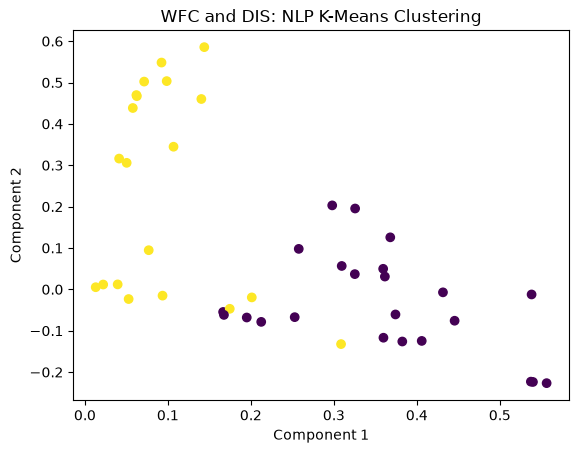

In [1]:
# NLP + K-Means: Wells Fargo (WFC) and Walt Disney (DIS)

# !pip install pandas scikit-learn matplotlib

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score

# Load dataset
df = pd.read_csv("Wells_Fargo_WFC_and_Walt_Disney_DIS_Report.csv")
print(df.head())
print(df.columns.tolist())

# Combine text columns
text_cols = df.select_dtypes(include="object").columns
df["Text"] = df[text_cols].fillna("").astype(str).agg(" ".join, axis=1)

# NLP: TF-IDF
tfidf = TfidfVectorizer(stop_words="english", max_features=3000)
X = tfidf.fit_transform(df["Text"])

# K-Means clustering
k = 2
model = KMeans(n_clusters=k, random_state=42, n_init=10)
df["Cluster"] = model.fit_predict(X)

# Results
print("\nCluster counts:\n", df["Cluster"].value_counts())
print("\nSilhouette score:", silhouette_score(X, df["Cluster"]))

# Top keywords per cluster
terms = tfidf.get_feature_names_out()
for i, center in enumerate(model.cluster_centers_):
    print(f"\nCluster {i} keywords:")
    print([terms[j] for j in center.argsort()[-10:][::-1]])

# Visualise clusters
coords = TruncatedSVD(n_components=2, random_state=42).fit_transform(X)
plt.scatter(coords[:, 0], coords[:, 1], c=df["Cluster"], cmap="viridis")
plt.title("WFC and DIS: NLP K-Means Clustering")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.show()

# Save results
df.to_csv("WFC_DIS_KMeans_Results.csv", index=False)